In [1]:
import torch, torchvision
print(torch.__version__, torchvision.__version__)
print("GPU :", torch.cuda.is_available())

2.11.0+cu130 0.26.0+cu130
GPU : True


In [2]:
from torchvision.datasets import EuroSAT

dataset = EuroSAT(root="data", download=True)
print(len(dataset))
print(dataset.classes)

100%|██████████| 94.3M/94.3M [00:01<00:00, 65.5MB/s]


27000
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


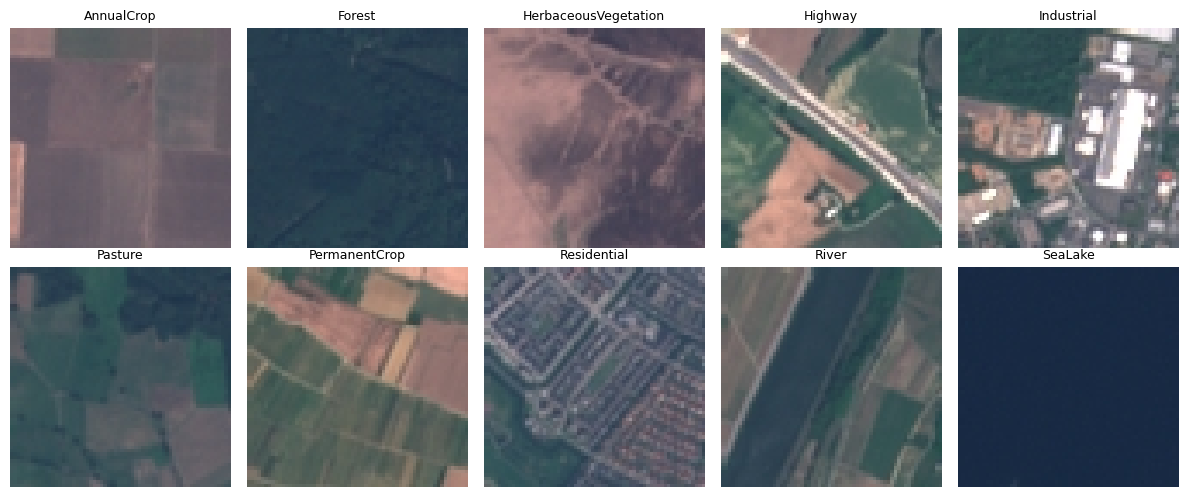

In [3]:
import numpy as np
import matplotlib.pyplot as plt

targets = np.array(dataset.targets)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for classe, ax in enumerate(axes.flat):
    idx = np.where(targets == classe)[0][0]
    img, _ = dataset[idx]
    ax.imshow(img)
    ax.set_title(dataset.classes[classe], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
pd.Series(targets).value_counts()

,count
0,3000
1,3000
2,3000
7,3000
9,3000
3,2500
6,2500
4,2500
8,2500
5,2000


In [5]:
arr = np.array(img)
arr.shape, arr.dtype, arr.min(), arr.max()

((64, 64, 3), dtype('uint8'), np.uint8(21), np.uint8(80))

In [6]:
for classe, nom in enumerate(dataset.classes):
    idxs = np.where(targets == classe)[0][:200]
    moyennes = [np.array(dataset[i][0]).mean(axis=(0, 1)) for i in idxs]
    r, g, b = np.mean(moyennes, axis=0)
    print(f"{nom:22s} R={r:5.1f}  G={g:5.1f}  B={b:5.1f}")

AnnualCrop             R=128.8  G=118.9  B=116.3
Forest                 R= 38.6  G= 63.6  B= 75.8
HerbaceousVegetation   R= 98.4  G= 98.7  B=103.8
Highway                R= 89.7  G= 97.6  B=103.7
Industrial             R=122.9  G=125.2  B=134.1
Pasture                R= 61.4  G= 87.4  B= 91.8
PermanentCrop          R=119.3  G=114.2  B=112.6
Residential            R= 99.5  G=103.4  B=112.5
River                  R= 66.3  G= 86.6  B= 97.1
SeaLake                R= 46.9  G= 71.7  B= 87.7


In [7]:
X_img = np.stack([np.array(dataset[i][0]) for i in range(len(dataset))])
y = np.array(dataset.targets)
print(X_img.shape, X_img.dtype, y.shape)



(27000, 64, 64, 3) uint8 (27000,)


In [8]:
mean_rgb = X_img.mean(axis=(1, 2))
std_rgb = X_img.std(axis=(1, 2))

gray = X_img.mean(axis=3, dtype=np.float32)
dx = np.abs(np.diff(gray, axis=2)).mean(axis=(1, 2))
dy = np.abs(np.diff(gray, axis=1)).mean(axis=(1, 2))
texture = np.column_stack([dx, dy])

print(mean_rgb.shape, std_rgb.shape, texture.shape)

(27000, 3) (27000, 3) (27000, 2)


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def evaluer(features, nom):
    Xtr, Xte, ytr, yte = train_test_split(
        features, y, test_size=0.2, stratify=y, random_state=42)
    clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    clf.fit(Xtr, ytr)
    pred = clf.predict(Xte)
    print(f"{nom:32s} {features.shape[1]:2d} variables  précision = {accuracy_score(yte, pred):.3f}")
    return pred, yte

evaluer(mean_rgb, "Couleur moyenne")
evaluer(np.hstack([mean_rgb, std_rgb]), "+ écart-type")
pred, yte = evaluer(np.hstack([mean_rgb, std_rgb, texture]), "+ texture")

Couleur moyenne                   3 variables  précision = 0.603
+ écart-type                      6 variables  précision = 0.778
+ texture                         8 variables  précision = 0.825


In [10]:
   import pandas as pd
   from sklearn.metrics import confusion_matrix

   cm = confusion_matrix(yte, pred)
   pd.DataFrame(cm, index=dataset.classes, columns=dataset.classes)

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,526,0,3,9,1,18,22,0,16,5
Forest,0,580,5,0,0,12,0,0,1,2
HerbaceousVegetation,2,2,438,19,17,10,74,16,22,0
Highway,33,0,24,243,30,21,50,27,72,0
Industrial,0,0,3,10,472,0,0,15,0,0
Pasture,4,5,18,9,0,351,4,0,9,0
PermanentCrop,19,0,46,32,7,17,361,6,12,0
Residential,0,0,4,11,9,0,2,574,0,0
River,26,6,6,80,14,19,10,1,336,2
SeaLake,7,2,1,1,0,2,0,0,12,575


In [11]:
AH, BH = evaluer(np.hstack([mean_rgb, std_rgb]), "+ écart-type")
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(AH, BH)
pd.DataFrame(cm, index=dataset.classes, columns=dataset.classes)

+ écart-type                      6 variables  précision = 0.778


,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,475,0,6,46,0,4,45,2,26,2
Forest,0,564,4,0,0,7,0,0,5,18
HerbaceousVegetation,18,4,429,26,0,14,60,10,6,9
Highway,19,2,13,202,13,9,32,27,73,3
Industrial,0,0,14,27,451,0,5,23,11,0
Pasture,19,21,9,20,0,353,16,0,19,3
PermanentCrop,44,0,62,44,0,5,313,8,9,0
Residential,2,0,36,70,34,0,11,526,6,0
River,19,2,22,65,2,8,18,4,339,16
SeaLake,4,7,5,0,0,0,0,0,6,549


In [12]:
def evaluer_multi(features, nom, n_repetitions=5):
    scores = []
    for seed in range(n_repetitions):
        Xtr, Xte, ytr, yte = train_test_split(
            features, y, test_size=0.2, stratify=y, random_state=seed)
        clf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1)
        clf.fit(Xtr, ytr)
        scores.append(accuracy_score(yte, clf.predict(Xte)))
    print(f"{nom:20s} {np.mean(scores):.3f} ± {np.std(scores):.3f}")

evaluer_multi(mean_rgb, "Couleur moyenne")
evaluer_multi(np.hstack([mean_rgb, std_rgb]), "+ écart-type")
evaluer_multi(np.hstack([mean_rgb, std_rgb, texture]), "+ texture")

Couleur moyenne      0.605 ± 0.005
+ écart-type         0.774 ± 0.006
+ texture            0.823 ± 0.005


In [14]:
X_flat = X_img.reshape(len(X_img), -1).astype(np.float32) / 255
print(X_flat.shape)

Xtr, Xte, ytr, yte = train_test_split(
    X_flat, y, test_size=0.2, stratify=y, random_state=42)

clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(Xtr, ytr)

(27000, 12288)


KeyboardInterrupt: 

In [15]:
from sklearn.neighbors import NearestCentroid
from sklearn.preprocessing import StandardScaler

feats = np.hstack([mean_rgb, std_rgb, texture])
Xtr, Xte, ytr, yte = train_test_split(
    feats, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(Xtr)
nc = NearestCentroid().fit(scaler.transform(Xtr), ytr)
print(f"Plus proche centroïde : {accuracy_score(yte, nc.predict(scaler.transform(Xte))):.3f}")

Plus proche centroïde : 0.489


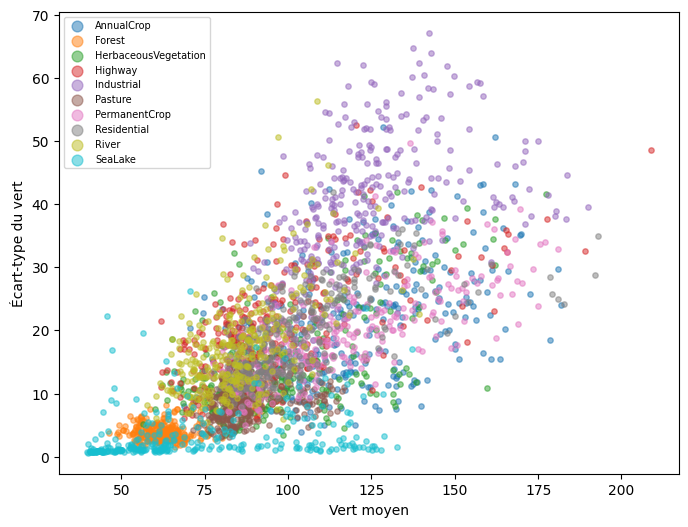

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
for classe, nom in enumerate(dataset.classes):
    idx = np.where(y == classe)[0][:300]
    ax.scatter(mean_rgb[idx, 1], std_rgb[idx, 1], s=15, alpha=0.5, label=nom)
ax.set_xlabel("Vert moyen")
ax.set_ylabel("Écart-type du vert")
ax.legend(fontsize=7, markerscale=2)
plt.show()

In [17]:
import torch

x = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print(x.shape, x.dtype)
print(x.mean(dim=0))
print(x.mean(dim=1))

torch.Size([2, 3]) torch.float32
tensor([2.5000, 3.5000, 4.5000])
tensor([2., 5.])


In [18]:
from torchvision import transforms

to_tensor = transforms.ToTensor()
img, label = dataset[0]
t = to_tensor(img)
print(t.shape, t.dtype, t.min(), t.max())

torch.Size([3, 64, 64]) torch.float32 tensor(0.3216) tensor(0.8000)


In [19]:
from torchvision.datasets import EuroSAT
from torch.utils.data import DataLoader

dataset_t = EuroSAT(root="data", download=True, transform=transforms.ToTensor())

x1, y1 = dataset_t[0]
print(x1.shape, y1)

loader = DataLoader(dataset_t, batch_size=64, shuffle=True)
xb, yb = next(iter(loader))
print(xb.shape, yb.shape)
print(len(loader))

torch.Size([3, 64, 64]) 0
torch.Size([64, 3, 64, 64]) torch.Size([64])
422


In [20]:
for melange in [False, True]:
    loader = DataLoader(dataset_t, batch_size=64, shuffle=melange)
    _, yb = next(iter(loader))
    print(f"shuffle={melange} :", yb[:20].tolist())

shuffle=False : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
shuffle=True : [6, 7, 7, 7, 8, 2, 5, 8, 5, 7, 3, 6, 3, 0, 2, 8, 1, 4, 7, 5]


In [21]:
import torch
import torch.nn as nn
from torchvision import transforms
from torchvision.datasets import EuroSAT

dataset_t = EuroSAT(root="data", download=True, transform=transforms.ToTensor())

x, label = dataset_t[0]
print(x.shape)

x = x.unsqueeze(0)
print(x.shape)

torch.Size([3, 64, 64])
torch.Size([1, 3, 64, 64])


In [22]:
conv = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, padding=1)

out = conv(x)
print(out.shape)
print(conv.weight.shape, conv.bias.shape)

torch.Size([1, 8, 64, 64])
torch.Size([8, 3, 3, 3]) torch.Size([8])


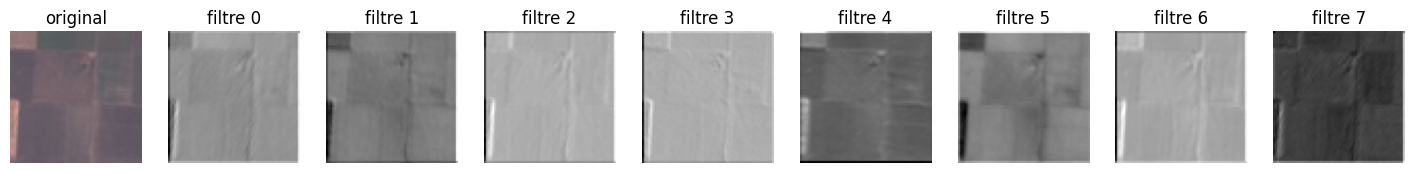

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 9, figsize=(18, 2.5))
axes[0].imshow(x[0].permute(1, 2, 0))
axes[0].set_title("original")
for i in range(8):
    axes[i + 1].imshow(out[0, i].detach(), cmap="gray")
    axes[i + 1].set_title(f"filtre {i}")
for ax in axes:
    ax.axis("off")
plt.show()

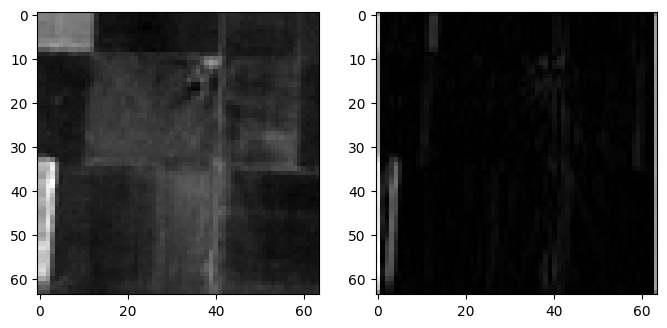

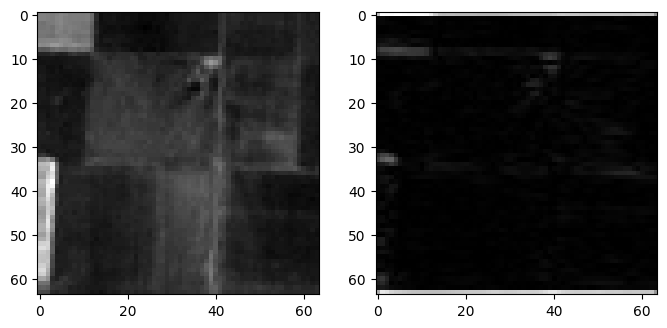

In [24]:
sobel = torch.tensor([[-1., 0., 1.],
                      [-2., 0., 2.],
                      [-1., 0., 1.]])

gris = x.mean(dim=1, keepdim=True)
bords = nn.functional.conv2d(gris, sobel.view(1, 1, 3, 3), padding=1)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(gris[0, 0], cmap="gray")
axes[1].imshow(bords[0, 0].abs(), cmap="gray")
plt.show()

sobelT = torch.tensor([[-1., -2., -1.],
                       [0., 0., 0.],
                       [1., 2., 1.]])

bords = nn.functional.conv2d(gris, sobelT.view(1, 1, 3, 3), padding=1)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(gris[0, 0], cmap="gray")
axes[1].imshow(bords[0, 0].abs(), cmap="gray")
plt.show()

In [25]:
sum(p.numel() for p in conv.parameters())

224

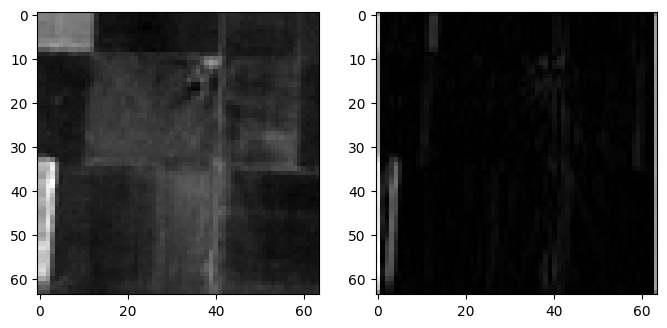

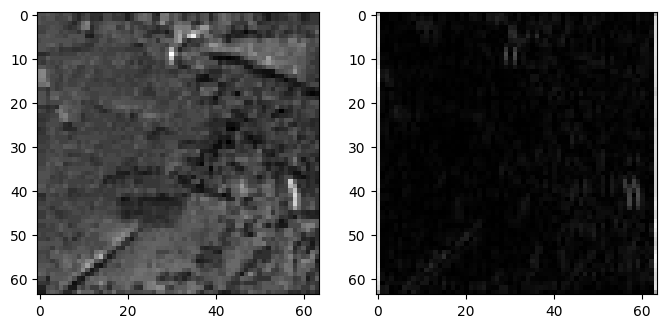

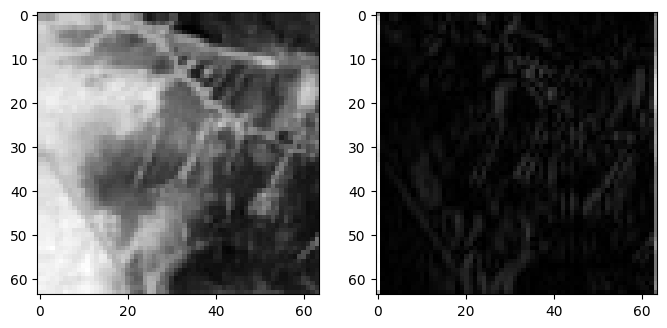

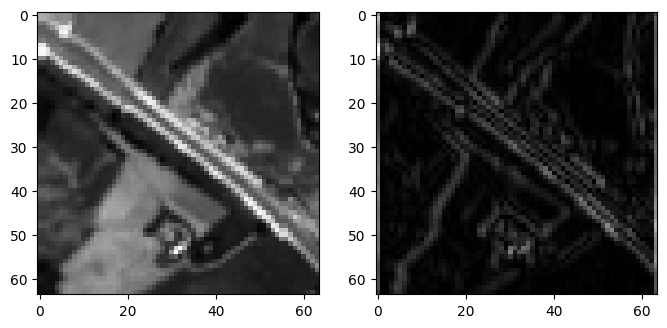

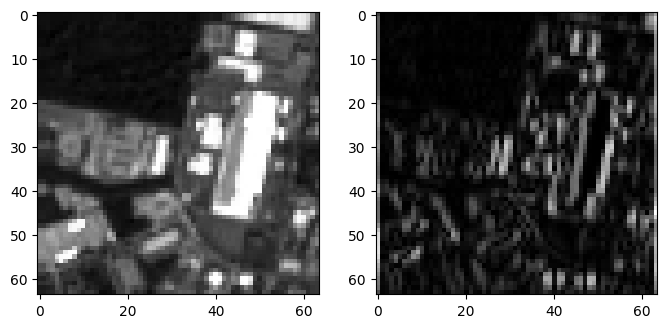

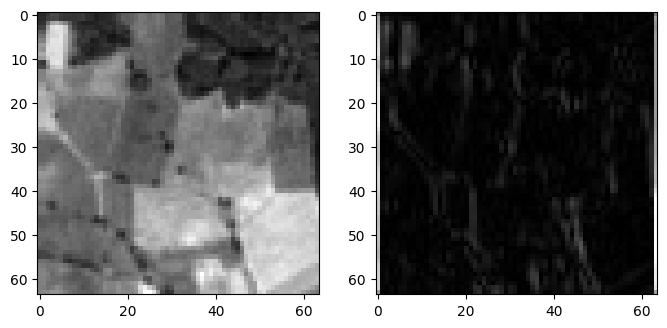

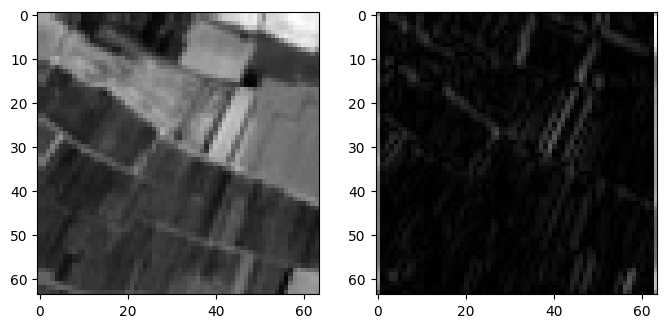

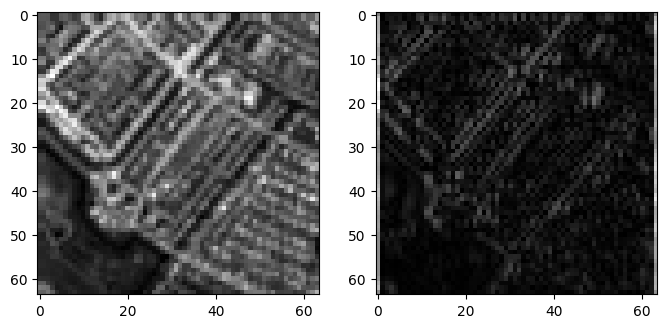

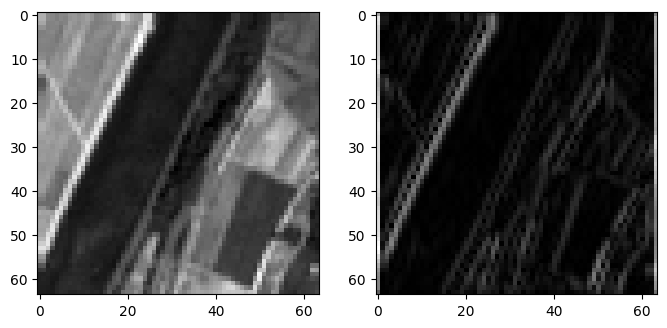

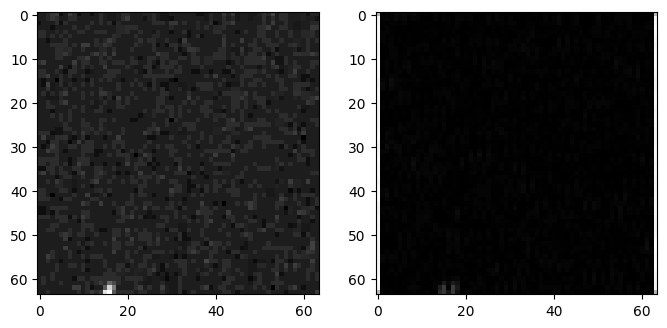

In [26]:
for classe, ax in enumerate(dataset.classes):
    idx = np.where(targets == classe)[0][0]
    img, _ = dataset_t[idx]
    OUT = conv(img.unsqueeze(0))
    # On calcule la moyenne sur dim=0 (les canaux de couleur) pour obtenir [1, 64, 64]
    gris = img.mean(dim=0, keepdim=True)
    bords = nn.functional.conv2d(gris.unsqueeze(0), sobel.view(1, 1, 3, 3), padding=1)
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(gris[0], cmap="gray")
    axes[1].imshow(bords[0, 0].abs().detach(), cmap="gray")
    plt.show()

In [27]:
class PetitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = PetitCNN()

In [28]:
x = torch.zeros(1, 3, 64, 64)
for couche in model.features:
    x = couche(x)
    print(f"{couche.__class__.__name__:10s} {tuple(x.shape)}")

print("paramètres :", sum(p.numel() for p in model.parameters()))

xb = torch.zeros(64, 3, 64, 64)
print(model(xb).shape)

Conv2d     (1, 16, 64, 64)
ReLU       (1, 16, 64, 64)
MaxPool2d  (1, 16, 32, 32)
Conv2d     (1, 32, 32, 32)
ReLU       (1, 32, 32, 32)
MaxPool2d  (1, 32, 16, 16)
Conv2d     (1, 64, 16, 16)
ReLU       (1, 64, 16, 16)
MaxPool2d  (1, 64, 8, 8)
paramètres : 549290
torch.Size([64, 10])


In [29]:
xb, yb =next(iter(DataLoader(dataset_t, batch_size=64, shuffle=True)))
with torch.no_grad():
  pred = model(xb).argmax(dim=1)

print(pred[:20].tolist())
print(yb[:20].tolist())
print("précision :", (pred == yb).float().mean().item())

[4, 9, 9, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 9, 4, 4, 4, 4, 4, 4]
[9, 4, 4, 6, 5, 1, 3, 8, 1, 8, 8, 0, 2, 7, 9, 1, 2, 1, 9, 3]
précision : 0.015625


In [30]:
import math

critere = nn.CrossEntropyLoss()

with torch.no_grad():
    scores = model(xb)
    perte = critere(scores, yb)

print(scores.shape)
print("perte :", perte.item())
print("perte attendue pour un modèle au hasard :", math.log(10))


torch.Size([64, 10])
perte : 2.2985377311706543
perte attendue pour un modèle au hasard : 2.302585092994046


In [31]:
print(torch.bincount(pred, minlength=10))
print("images de classe 2 dans le lot :", (yb == 2).sum().item())
print("moyenne des scores :", scores.mean(dim=0))
print("variation entre images :", scores.std(dim=0))

tensor([ 0,  0,  0,  0, 51,  0,  0,  0,  0, 13])
images de classe 2 dans le lot : 5
moyenne des scores : tensor([-0.0503, -0.0436,  0.0364, -0.0648,  0.0558, -0.0636, -0.0852,  0.0473,
        -0.0609,  0.0513])
variation entre images : tensor([0.0022, 0.0012, 0.0018, 0.0025, 0.0032, 0.0011, 0.0012, 0.0031, 0.0010,
        0.0025])


In [32]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader

y = np.array(dataset_t.targets)
idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)

train_loader = DataLoader(Subset(dataset_t, idx_train), batch_size=64, shuffle=True)
test_loader = DataLoader(Subset(dataset_t, idx_test), batch_size=256, shuffle=False)
print(len(idx_train), len(idx_test))

21600 5400


In [33]:
model = PetitCNN()
critere = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(model.parameters(), lr=1e-3)

xb, yb = next(iter(train_loader))

for etape in range(50):
    optimiseur.zero_grad()
    perte = critere(model(xb), yb)
    perte.backward()
    optimiseur.step()
    if etape % 5 == 0:
        print(etape, round(perte.item(), 4))

0 2.3077
5 2.183
10 2.0458
15 1.8062
20 1.4524
25 1.1502
30 0.9176
35 0.7545
40 0.6096
45 0.4763


In [34]:
model = PetitCNN()
critere = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(model.parameters(), lr=1e-6)

xb, yb = next(iter(train_loader))

for etape in range(50):
    optimiseur.zero_grad()
    perte = critere(model(xb), yb)
    perte.backward()
    optimiseur.step()
    if etape % 5 == 0:
        print(etape, round(perte.item(), 4))

0 2.3041
5 2.3038
10 2.3035
15 2.3033
20 2.303
25 2.3027
30 2.3024
35 2.3022
40 2.3019
45 2.3016


In [35]:
model = PetitCNN()
critere = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(model.parameters(), lr=1)

xb, yb = next(iter(train_loader))

for etape in range(50):
    optimiseur.zero_grad()
    perte = critere(model(xb), yb)
    perte.backward()
    optimiseur.step()
    if etape % 5 == 0:
        print(etape, round(perte.item(), 4))

0 2.309
5 7505.8257
10 1322.3035
15 7.7683
20 7.5333
25 683.4297
30 4.9764
35 3.746
40 3.0053
45 2.5777


In [37]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device :", device)

model = PetitCNN().to(device)
critere = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(model.parameters(), lr=1e-3)

def precision_test(model, loader):
    model.eval()
    bonnes, total = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb).argmax(dim=1)
            bonnes += (pred == yb).sum().item()
            total += len(yb)
    return bonnes / total

device : cuda


In [36]:
for epoch in range(1, 5):
    model.train()
    perte_totale = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimiseur.zero_grad()
        perte = critere(model(xb), yb)
        perte.backward()
        optimiseur.step()
        perte_totale += perte.item() * len(yb)
    perte_moy = perte_totale / len(train_loader.dataset)
    acc = precision_test(model, test_loader)
    print(f"epoch {epoch} : perte entraînement = {perte_moy:.3f} | précision test = {acc:.3f}")

device : cuda
epoch 1 : perte entraînement = 1.347 | précision test = 0.648


KeyboardInterrupt: 

In [38]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device :", device)

model = PetitCNN().to(device)
critere = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(model.parameters(), lr=1e-3)


device : cuda


In [ ]:
for epoch in range(1, 16):
    model.train()
    perte_totale = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimiseur.zero_grad()
        perte = critere(model(xb), yb)
        perte.backward()
        optimiseur.step()
        perte_totale += perte.item() * len(yb)
    perte_moy = perte_totale / len(train_loader.dataset)
    acc = precision_test(model, test_loader)
    print(f"epoch {epoch} : perte entraînement = {perte_moy:.3f} | précision test = {acc:.3f}")

In [39]:
import pandas as pd
from sklearn.metrics import confusion_matrix

def evaluer_complet(model, loader):
    model.eval()
    preds, vraies, perte_tot = [], [], 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            sortie = model(xb)
            perte_tot += critere(sortie, yb).item() * len(yb)
            preds.append(sortie.argmax(dim=1).cpu())
            vraies.append(yb.cpu())
    preds = torch.cat(preds).numpy()
    vraies = torch.cat(vraies).numpy()
    return perte_tot / len(vraies), (preds == vraies).mean(), preds, vraies

train_eval_loader = DataLoader(Subset(dataset_t, idx_train), batch_size=256, shuffle=False)

p_tr, a_tr, _, _ = evaluer_complet(model, train_eval_loader)
p_te, a_te, pred_te, vrai_te = evaluer_complet(model, test_loader)

print(f"entraînement : perte = {p_tr:.3f} | précision = {a_tr:.3f}")
print(f"test         : perte = {p_te:.3f} | précision = {a_te:.3f}")

entraînement : perte = 2.303 | précision = 0.054
test         : perte = 2.303 | précision = 0.054


In [40]:
cm = confusion_matrix(vrai_te, pred_te)
pd.DataFrame(cm, index=dataset_t.classes, columns=dataset_t.classes)

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,0,540,0,59,0,0,0,1,0,0
Forest,0,17,0,572,0,0,0,0,0,11
HerbaceousVegetation,0,531,0,68,0,0,0,0,0,1
Highway,0,394,0,98,0,0,0,1,0,7
Industrial,0,468,0,30,0,0,0,2,0,0
Pasture,0,209,0,189,0,0,0,0,0,2
PermanentCrop,0,473,0,27,0,0,0,0,0,0
Residential,0,588,0,12,0,0,0,0,0,0
River,0,353,0,138,0,0,0,2,0,7
SeaLake,0,172,0,249,0,0,0,0,0,179


In [41]:
acc_classe = cm.diagonal() / cm.sum(axis=1)
for nom, a in zip(dataset_t.classes, acc_classe):
    print(f"{nom:22s} {a:.3f}")

AnnualCrop             0.000
Forest                 0.028
HerbaceousVegetation   0.000
Highway                0.196
Industrial             0.000
Pasture                0.000
PermanentCrop          0.000
Residential            0.000
River                  0.000
SeaLake                0.298


In [42]:
conf = []
for i in range(10):
    for j in range(10):
        if i != j:
            conf.append((cm[i, j], dataset_t.classes[i], dataset_t.classes[j]))
for n, vrai, predit in sorted(conf, reverse=True)[:6]:
    print(f"{vrai:22s} pris pour {predit:22s} : {n} images")

i = dataset_t.classes.index("Highway")
print(pd.Series(cm[i], index=dataset_t.classes).sort_values(ascending=False))

Residential            pris pour Forest                 : 588 images
Forest                 pris pour Highway                : 572 images
AnnualCrop             pris pour Forest                 : 540 images
HerbaceousVegetation   pris pour Forest                 : 531 images
PermanentCrop          pris pour Forest                 : 473 images
Industrial             pris pour Forest                 : 468 images
Forest                  394
Highway                  98
SeaLake                   7
Residential               1
AnnualCrop                0
HerbaceousVegetation      0
Pasture                   0
Industrial                0
PermanentCrop             0
River                     0
dtype: int64


In [43]:
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
    transforms.ToTensor(),
])

dataset_aug = EuroSAT(root="data", download=False, transform=train_tf)
train_loader_aug = DataLoader(Subset(dataset_aug, idx_train),
                              batch_size=64, shuffle=True, num_workers=2)

In [44]:
def entrainer(model, loader, epochs):
    optimiseur = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimiseur.zero_grad()
            critere(model(xb), yb).backward()
            optimiseur.step()
        acc = precision_test(model, test_loader)
        print(f"epoch {epoch} : précision test = {acc:.3f}")

torch.manual_seed(0)
model_aug = PetitCNN().to(device)
entrainer(model_aug, train_loader_aug, 15)

epoch 1 : précision test = 0.619


KeyboardInterrupt: 

In [47]:
p_tr, a_tr, _, _ = evaluer_complet(model_aug, train_eval_loader)
p_te, a_te, pred_aug, vrai_aug = evaluer_complet(model_aug, test_loader)
print(f"entraînement : perte = {p_tr:.3f} | précision = {a_tr:.3f}")
print(f"test         : perte = {p_te:.3f} | précision = {a_te:.3f}")

entraînement : perte = 0.845 | précision = 0.689
test         : perte = 0.858 | précision = 0.687


In [48]:
cm_aug = confusion_matrix(vrai_aug, pred_aug)

conf = [(cm_aug[i, j], dataset_t.classes[i], dataset_t.classes[j])
        for i in range(10) for j in range(10) if i != j]
for n, vrai, predit in sorted(conf, reverse=True)[:6]:
    print(f"{vrai:22s} pris pour {predit:22s} : {n} images")

acc_classe = cm_aug.diagonal() / cm_aug.sum(axis=1)
for nom, a in zip(dataset_t.classes, acc_classe):
    print(f"{nom:22s} {a:.3f}")

Highway                pris pour River                  : 115 images
HerbaceousVegetation   pris pour PermanentCrop          : 110 images
Industrial             pris pour Residential            : 84 images
PermanentCrop          pris pour AnnualCrop             : 74 images
River                  pris pour Pasture                : 73 images
HerbaceousVegetation   pris pour Residential            : 73 images
AnnualCrop             0.773
Forest                 0.908
HerbaceousVegetation   0.410
Highway                0.302
Industrial             0.812
Pasture                0.660
PermanentCrop          0.506
Residential            0.965
River                  0.592
SeaLake                0.845


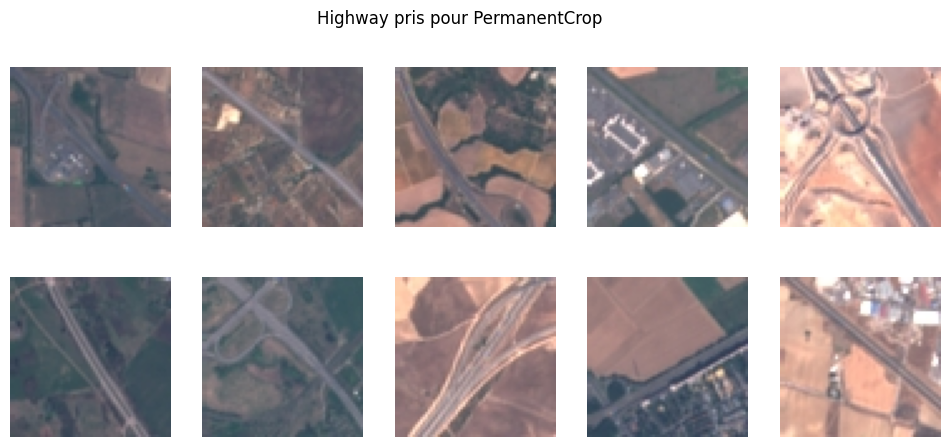

In [49]:
i_h = dataset_t.classes.index("Highway")
i_p = dataset_t.classes.index("PermanentCrop")
mal = np.where((vrai_aug == i_h) & (pred_aug == i_p))[0][:10]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for k, ax in zip(mal, axes.flat):
    ax.imshow(dataset[idx_test[k]][0])
    ax.axis("off")
plt.suptitle("Highway pris pour PermanentCrop")
plt.show()

In [50]:
def entrainer(model, loader, epochs, lr=1e-3):
    optimiseur = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=epochs)
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimiseur.zero_grad()
            critere(model(xb), yb).backward()
            optimiseur.step()
        scheduler.step()
        acc = precision_test(model, test_loader)
        print(f"epoch {epoch:2d} : lr = {scheduler.get_last_lr()[0]:.5f} | précision test = {acc:.3f}")

torch.manual_seed(0)
model_long = PetitCNN().to(device)
entrainer(model_long, train_loader_aug, 40)

epoch  1 : lr = 0.00100 | précision test = 0.629
epoch  2 : lr = 0.00099 | précision test = 0.661
epoch  3 : lr = 0.00099 | précision test = 0.757
epoch  4 : lr = 0.00098 | précision test = 0.745
epoch  5 : lr = 0.00096 | précision test = 0.765
epoch  6 : lr = 0.00095 | précision test = 0.789
epoch  7 : lr = 0.00093 | précision test = 0.806
epoch  8 : lr = 0.00090 | précision test = 0.819
epoch  9 : lr = 0.00088 | précision test = 0.817
epoch 10 : lr = 0.00085 | précision test = 0.832
epoch 11 : lr = 0.00082 | précision test = 0.830
epoch 12 : lr = 0.00079 | précision test = 0.836
epoch 13 : lr = 0.00076 | précision test = 0.841
epoch 14 : lr = 0.00073 | précision test = 0.842
epoch 15 : lr = 0.00069 | précision test = 0.857
epoch 16 : lr = 0.00065 | précision test = 0.847
epoch 17 : lr = 0.00062 | précision test = 0.842
epoch 18 : lr = 0.00058 | précision test = 0.875
epoch 19 : lr = 0.00054 | précision test = 0.844
epoch 20 : lr = 0.00050 | précision test = 0.879
epoch 21 : lr = 0.00

In [51]:
torch.save(model_aug.state_dict(), "modele_cnn_aug.pt")

from google.colab import files
files.download("modele_cnn_aug.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

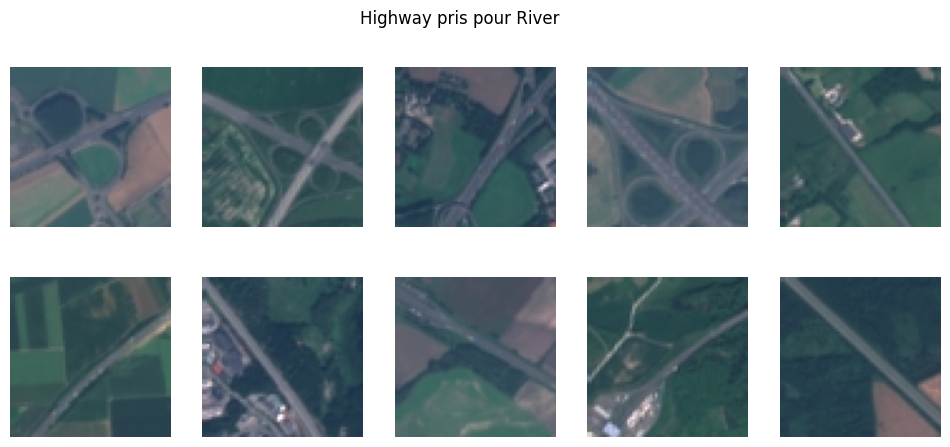

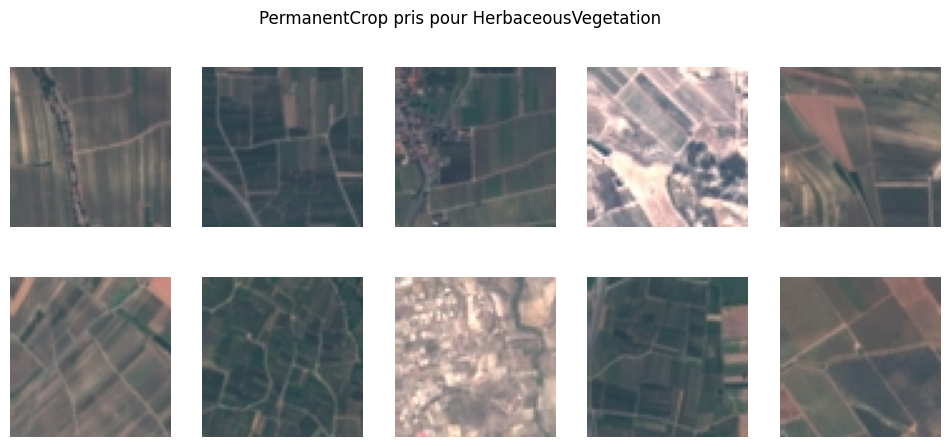

In [53]:
def montrer_erreurs(vrai_nom, predit_nom, n=10):
    i = dataset_t.classes.index(vrai_nom)
    j = dataset_t.classes.index(predit_nom)
    positions = np.where((vrai_aug == i) & (pred_aug == j))[0][:n]
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for k, ax in zip(positions, axes.flat):
        ax.imshow(dataset[idx_test[k]][0])
        ax.axis("off")
    plt.suptitle(f"{vrai_nom} pris pour {predit_nom}")
    plt.show()

montrer_erreurs("Highway", "River")
montrer_erreurs("PermanentCrop", "HerbaceousVegetation")

In [55]:
p_tr, a_tr, _, _ = evaluer_complet(model_long, train_eval_loader)
p_te, a_te, pred_aug, vrai_aug = evaluer_complet(model_long, test_loader)
print(f"entraînement : perte = {p_tr:.3f} | précision = {a_tr:.3f}")
print(f"test         : perte = {p_te:.3f} | précision = {a_te:.3f}")

entraînement : perte = 0.201 | précision = 0.929
test         : perte = 0.264 | précision = 0.909


---


# Essayons nous ici avec **ResNet18**

---





In [56]:
import numpy as np
import torch, torch.nn as nn
from torchvision import transforms, models
from torchvision.datasets import EuroSAT
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device :", device)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TAILLE = 128

tf_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomChoice([transforms.RandomRotation((a,   a)) for a in (0, 90, 180, 270)]),
    transforms.Resize(TAILLE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
tf_test = transforms.Compose([
    transforms.Resize(TAILLE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

ds_train = EuroSAT(root="data", download=True, transform=tf_train)
ds_test = EuroSAT(root="data", download=True, transform=tf_test)

y = np.array(ds_train.targets)
idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)

train_loader = DataLoader(Subset(ds_train, idx_train), batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(Subset(ds_test, idx_test), batch_size=256, shuffle=False, num_workers=2)
print(len(idx_train), len(idx_test))

device : cuda
21600 5400


In [57]:
modele = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
modele.fc = nn.Linear(modele.fc.in_features, 10)
modele = modele.to(device)
print("paramètres :", sum(p.numel() for p in modele.parameters()))

critere = nn.CrossEntropyLoss()

def precision(model, loader):
    model.eval()
    bonnes, total = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            bonnes += (model(xb).argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return bonnes / total

def entrainer_tl(model, loader, epochs, lr):
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            critere(model(xb), yb).backward()
            opt.step()
        sched.step()
        print(f"epoch {epoch:2d} | précision test = {precision(model, test_loader):.3f}")

torch.manual_seed(0)
entrainer_tl(modele, train_loader, epochs=8, lr=3e-4)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


paramètres : 11181642
epoch  1 | précision test = 0.938
epoch  2 | précision test = 0.964
epoch  3 | précision test = 0.969
epoch  4 | précision test = 0.977
epoch  5 | précision test = 0.980
epoch  6 | précision test = 0.983
epoch  7 | précision test = 0.984
epoch  8 | précision test = 0.985


In [1]:
import numpy as np
import torch, torch.nn as nn
from torchvision import transforms, models
from torchvision.datasets import EuroSAT
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device :", device)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TAILLE = 64

tf_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
    transforms.Resize(TAILLE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
tf_test = transforms.Compose([
    transforms.Resize(TAILLE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

ds_train = EuroSAT(root="data", download=True, transform=tf_train)
ds_test = EuroSAT(root="data", download=True, transform=tf_test)

y = np.array(ds_train.targets)
idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)

train_loader = DataLoader(Subset(ds_train, idx_train), batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(Subset(ds_test, idx_test), batch_size=256, shuffle=False, num_workers=2)
print(len(idx_train), len(idx_test))

modele = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
modele.fc = nn.Linear(modele.fc.in_features, 10)
modele = modele.to(device)
print("paramètres :", sum(p.numel() for p in modele.parameters()))

critere = nn.CrossEntropyLoss()

def precision(model, loader):
    model.eval()
    bonnes, total = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            bonnes += (model(xb).argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return bonnes / total

def entrainer_tl(model, loader, epochs, lr):
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            critere(model(xb), yb).backward()
            opt.step()
        sched.step()
        print(f"epoch {epoch:2d} | précision test = {precision(model, test_loader):.3f}")

torch.manual_seed(0)
entrainer_tl(modele, train_loader, epochs=8, lr=3e-4)

device : cuda


100%|██████████| 94.3M/94.3M [00:01<00:00, 80.0MB/s]


21600 5400
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 146MB/s]


paramètres : 11181642
epoch  1 | précision test = 0.951
epoch  2 | précision test = 0.951
epoch  3 | précision test = 0.968
epoch  4 | précision test = 0.957
epoch  5 | précision test = 0.967
epoch  6 | précision test = 0.977
epoch  7 | précision test = 0.980
epoch  8 | précision test = 0.982


In [2]:
torch.manual_seed(0)
sans_pretrain = models.resnet18(weights=None)
sans_pretrain.fc = nn.Linear(sans_pretrain.fc.in_features, 10)
sans_pretrain = sans_pretrain.to(device)
entrainer_tl(sans_pretrain, train_loader, epochs=8, lr=3e-4)

epoch  1 | précision test = 0.751
epoch  2 | précision test = 0.765
epoch  3 | précision test = 0.792
epoch  4 | précision test = 0.871
epoch  5 | précision test = 0.849
epoch  6 | précision test = 0.862
epoch  7 | précision test = 0.911
epoch  8 | précision test = 0.936


In [3]:
from sklearn.metrics import confusion_matrix

def predire(model, loader):
    model.eval()
    P, V = [], []
    with torch.no_grad():
        for xb, yb in loader:
            P.append(model(xb.to(device)).argmax(dim=1).cpu())
            V.append(yb)
    return torch.cat(P).numpy(), torch.cat(V).numpy()

pred, vrai = predire(modele, test_loader)
cm = confusion_matrix(vrai, pred)
for nom, a in zip(ds_test.classes, cm.diagonal() / cm.sum(axis=1)):
    print(f"{nom:22s} {a:.3f}")

AnnualCrop             0.970
Forest                 0.995
HerbaceousVegetation   0.985
Highway                0.990
Industrial             0.994
Pasture                0.968
PermanentCrop          0.954
Residential            0.992
River                  0.968
SeaLake                0.998


In [4]:
torch.save(modele.state_dict(), "resnet18_eurosat.pt")
from google.colab import files
files.download("resnet18_eurosat.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>